# Lab 6 — Localization: simulation and real odometry

The robot follows the digits **48** using wheel encoders. This report compares the simulation and real-robot logs from `trajectory_48_sim_segments.qrs` and `trajectory_48_real_segments.qrs`.

The files `week6_48_sim.txt` and `week6_48_real.txt` contain `x, y, time` in metres, metres and milliseconds. Keep both files beside the notebook, or upload them when using Colab.

Odometry uses `path = (theta_r + theta_l) * r / 2` and `heading = (theta_r - theta_l) * r / B`. Position is updated using the distance increment and the average heading during that increment. The left encoder is E4 and the right encoder is E3.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sim_file = Path('week6_48_sim.txt')
real_file = Path('week6_48_real.txt')

if not (sim_file.exists() and real_file.exists()):
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Put both log files in the notebook working folder.') from None
    files.upload()

sim = np.loadtxt(sim_file, delimiter=',', ndmin=2)
real = np.loadtxt(real_file, delimiter=',', ndmin=2)

for name, data in [('Simulation', sim), ('Real robot', real)]:
    if data.shape[1] != 3 or len(data) < 2 or not np.isfinite(data).all():
        raise ValueError(f'{name}: expected at least two valid x,y,time rows.')
    if not np.all(np.diff(data[:, 2]) > 0):
        raise ValueError(f'{name}: timestamps must increase without restarting.')

x_sim, y_sim, time_sim = sim.T
x_real, y_real, time_real = real.T
time_sim = (time_sim - time_sim[0]) / 1000
time_real = (time_real - time_real[0]) / 1000

print(f'Simulation: {len(sim)} samples, {time_sim[-1]:.2f} s')
print(f'Real robot: {len(real)} samples, {time_real[-1]:.2f} s')

Simulation: 3200 samples, 63.98 s
Real robot: 468 samples, 53.60 s


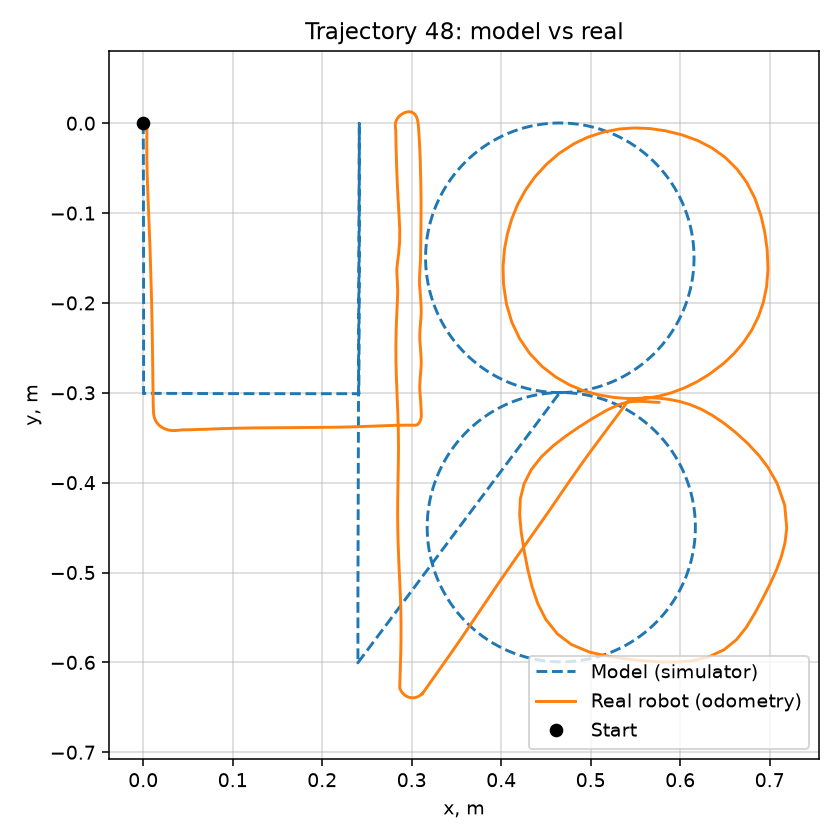

In [2]:
# Recorded trajectories, including the transfer between digits
plt.figure(figsize=(6, 6))
plt.plot(x_sim, y_sim, '--', label='Model (simulator)')
plt.plot(x_real, y_real, label='Real robot (odometry)')
plt.plot(0, 0, 'ko', label='Start')
plt.xlabel('x, m')
plt.ylabel('y, m')
plt.title('Trajectory 48: model vs real')
plt.axis('equal')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Error between model and real

The first plot compares positions at the same elapsed time. Different speeds and pauses affect this error. The second compares positions after the same cumulative distance travelled, reducing the effect of timing differences.

Both comparisons use only the overlapping range of the logs. Equal distance does not always mean the same part of the digit when the path lengths differ. These are differences between two odometry estimates, not errors against a measured physical path. The connecting movement between digits is included.

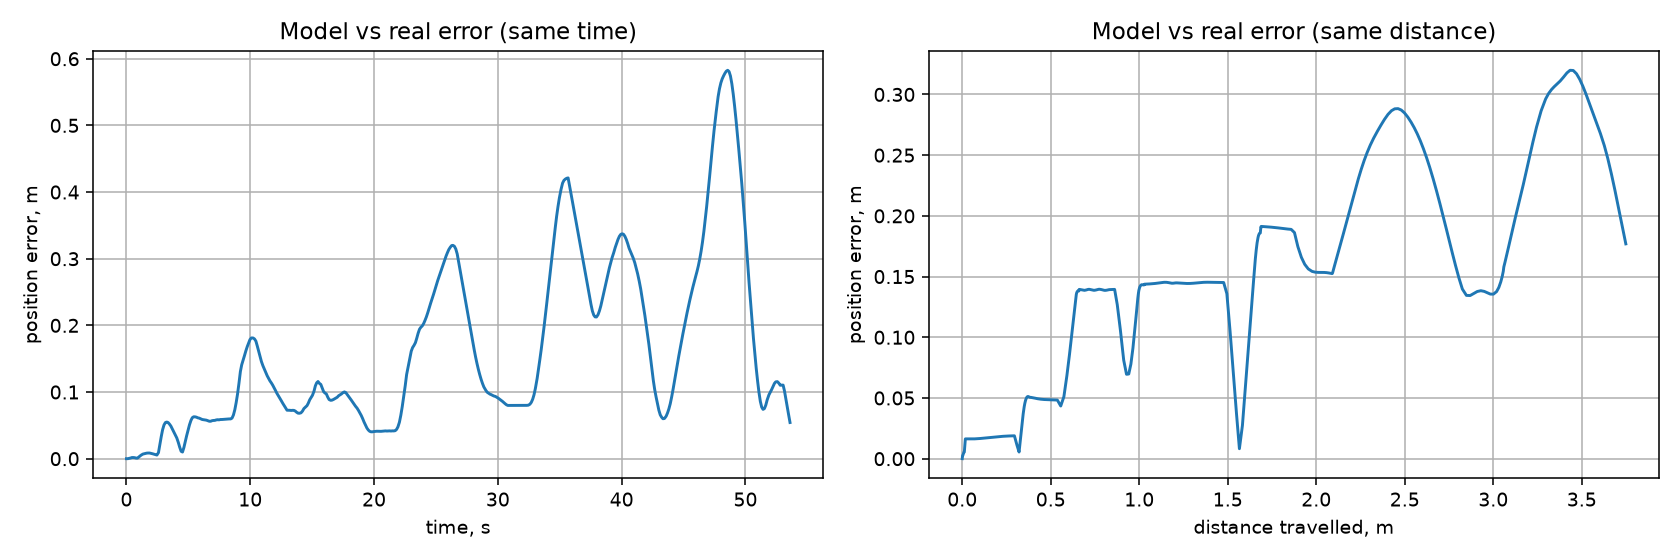

Final odometry difference (sim vs real): 0.109 m
Max error, same time:     0.583 m
Max error, same distance: 0.320 m
Path length: sim 3.76 m, real 4.01 m
Comparison ranges: 0–53.60 s and 0–3.75 m


In [3]:
# 1. Position error at the same elapsed time
shared_time = time_real <= min(time_sim[-1], time_real[-1])
comparison_time = time_real[shared_time]
sim_x_time = np.interp(comparison_time, time_sim, x_sim)
sim_y_time = np.interp(comparison_time, time_sim, y_sim)
error_time = np.hypot(x_real[shared_time] - sim_x_time,
                      y_real[shared_time] - sim_y_time)

# 2. Position error at the same cumulative distance travelled
def arc_length(x, y):
    return np.r_[0.0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]

distance_sim = arc_length(x_sim, y_sim)
distance_real = arc_length(x_real, y_real)
# Remove repeated distances caused by pauses before interpolation.
sim_moving = np.r_[True, np.diff(distance_sim) > 0]
real_moving = np.r_[True, np.diff(distance_real) > 0]
shared_distance = real_moving & (distance_real <= min(distance_sim[-1], distance_real[-1]))
comparison_distance = distance_real[shared_distance]
sim_x_distance = np.interp(comparison_distance, distance_sim[sim_moving], x_sim[sim_moving])
sim_y_distance = np.interp(comparison_distance, distance_sim[sim_moving], y_sim[sim_moving])
error_distance = np.hypot(x_real[shared_distance] - sim_x_distance,
                          y_real[shared_distance] - sim_y_distance)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(comparison_time, error_time)
ax[0].set_title('Model vs real error (same time)')
ax[0].set_xlabel('time, s')
ax[0].set_ylabel('position error, m')
ax[1].plot(comparison_distance, error_distance)
ax[1].set_title('Model vs real error (same distance)')
ax[1].set_xlabel('distance travelled, m')
ax[1].set_ylabel('position error, m')
for axis in ax:
    axis.grid(True)
fig.tight_layout()
plt.show()

endpoint_difference = np.hypot(x_real[-1] - x_sim[-1], y_real[-1] - y_sim[-1])
print(f'Final odometry difference (sim vs real): {endpoint_difference:.3f} m')
print(f'Max error, same time:     {error_time.max():.3f} m')
print(f'Max error, same distance: {error_distance.max():.3f} m')
print(f'Path length: sim {distance_sim[-1]:.2f} m, real {distance_real[-1]:.2f} m')
print(f'Comparison ranges: 0–{comparison_time[-1]:.2f} s and 0–{comparison_distance[-1]:.2f} m')

## Measured endpoint

No tape measurement has been supplied for this run. Enter the measured final coordinates below in metres, with x along the initial forward direction and y to the left. This gives an independent check of the real robot's odometry.

In [4]:
measured_x = None
measured_y = None

print(f'Simulator endpoint:    ({x_sim[-1]:.3f}, {y_sim[-1]:.3f}) m')
print(f'Real odometry endpoint: ({x_real[-1]:.3f}, {y_real[-1]:.3f}) m')
if measured_x is None or measured_y is None:
    print('Tape-measured endpoint: not provided.')
else:
    measured_error = np.hypot(x_real[-1] - measured_x, y_real[-1] - measured_y)
    print(f'Measured endpoint: ({measured_x:.3f}, {measured_y:.3f}) m')
    print(f'Odometry error against tape measurement: {measured_error:.3f} m')

Simulator endpoint:    (0.468, -0.300) m
Real odometry endpoint: (0.576, -0.311) m
Tape-measured endpoint: not provided.


## Discussion

The simulation took **63.98 s**, while the real run took **53.60 s**. The maximum position difference was **0.583 m at equal time** and **0.320 m at equal distance**. The final endpoints differed by **0.109 m**.

The logged path lengths were **3.76 m** in simulation and **4.01 m** on the robot. Comparing at equal distance reduces the effect of their different speeds, but differences in path length can still shift which parts of the digits are compared. Motor response, wheel slip and wheel-dimension errors are possible contributors; these logs alone do not establish the cause. A tape measurement is still needed to assess the real robot's endpoint accuracy.